# LM11 Lab — Eigen-decomposition and PCA

Companion notebook to **From Calculus to Kelly, LM11**. It repairs the sector closes, rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Sector closes and the repair of the wrongly served ones; the U28 sample, $T$ and $A$ |
| 2 | The case (Exhibit 1) |
| 3 | Eigenpairs by hand and with `eigh` (Example 1, Exhibit 2) |
| 4 | LM7's covariance matrix in its own axes (Example 2, Exhibit 3) |
| 5 | Rank-one pieces, $Q^{\top}Q=I$ and the sign rule (Example 3) |
| 6 | The Rayleigh quotient and condition numbers (Exhibit 4, Exhibit 5, Example 4) |
| 7 | PCA of U28 (Example 5, Exhibit 6, Exhibit 7, Exhibit 8, Example 6) |
| 8 | Overlapping indices (Example 7, Exhibit 9) |
| 9 | Eigenvalue gaps and stability (Example 8, Exhibit 10, Exhibit 11, Exhibit 12) |
| 10 | The inverse of $\hat\Sigma$ (Example 9, Example 10, Exhibit 13, Exhibit 14) |
| 11 | Practice problems 5–12 |
| 12 | Extension: the first component's share over rolling windows |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `sectors_close_raw.csv` (the daily closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, empty where a series has no close), `sectors_close_repairs.csv` (the 561 closes that FinMind serves wrongly, with their 13:30:00 values from `TaiwanStockEvery5SecondsIndex`), and the 0050, 00631L and 00679B closes and dividends of Volume I. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** U28 = the 28 leaf sector indices (all 30 except the aggregates Electronic and ChemicalBiotechnologyMedicalCare). Daily simple returns between consecutive TAIEX-calendar dates, closes 2008-12-01 to 2026-10-08; covariance with divisor $T$; $A=T/\text{years}$ with years = calendar days / 365.25. Eigenvalues descending; every eigenvector signed so that its entry largest in absolute value is positive (on a tie, the first tied entry).

In [1]:
from datetime import date
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
START, END = "2008-12-01", "2026-10-08"
AGG = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
ELEC8 = ["Semiconductor", "ComputerPeripheralEquipment", "Optoelectronic", "CommunicationsInternet",
         "ElectronicPartsComponents", "ElectronicProductsDistribution", "InformationService", "OtherElectronic"]
S3 = ["Semiconductor", "FinancialInsurance", "Food"]
S5 = S3 + ["Plastics", "ShippingTransportation"]
pl.Config.set_tbl_rows(40)
pl.Config.set_float_precision(4)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def cov0(x):
    # sample covariance matrix with divisor T (rows are dates)
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]

def corr(s):
    d = np.sqrt(np.diag(s))
    return s / np.outer(d, d)

def sign_rule(v):
    # the entry largest in absolute value is positive; on a tie, the first tied entry
    a = np.abs(v)
    i = int(np.flatnonzero(a >= a.max() * (1 - 1e-12))[0])
    return v if v[i] > 0 else -v

def eig_desc(m):
    # eigenvalues of a symmetric matrix, largest first, eigenvectors (columns) signed by the sign rule
    lam, q = np.linalg.eigh(m)
    lam, q = lam[::-1], q[:, ::-1]
    return lam.copy(), np.column_stack([sign_rule(q[:, k]) for k in range(q.shape[1])])

def spec_norm(m):
    return float(np.abs(np.linalg.eigvalsh(m)).max())

## Part 1 — Sector closes, the repair, and the U28 sample

FinMind serves some sector-index closes copied from another date or from another series (project/PITFALLS.md §3 in the repository). **Rule:** every close listed in `sectors_close_repairs.csv` is replaced by its `close_1330`, the official 13:30:00 value of `TaiwanStockEvery5SecondsIndex`. On FinMind's free plan that dataset is not available, `close_1330` is empty, and the cell drops those closes instead. Returns are taken between consecutive TAIEX-calendar dates, so a dropped close removes the returns into and out of its date.

With every value present, the repaired closes equal the book's (`data/vol2_series.py`) cell for cell: 561 closes replaced, 524 of them in U28 from 2008-12-01, on 38 dates. On the free plan U28's sample keeps $T=4{,}307$ of the 4,382 returns ($A=241.28$), and only numbers computed inside a window without a listed close keep their values: 7–10 April 2025, December 2008, the last 250 returns and the calendar years 2014, 2023, 2024 and 2026. Every full-sample, half-sample and per-year number below changes, and so do the cosines against the full sample (Getting Started, "Fetch the data"). The checks against the module's printed values run only when no close is dropped.

In [2]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
closes = raw
for sid in sorted(set(rep["id"].to_list())):
    fix = rep.filter(pl.col("id") == sid).select("date", pl.col("close_1330").alias("_fix"), pl.lit(True).alias("_listed"))
    closes = (closes.join(fix, on="date", how="left")
                    .with_columns(pl.when(pl.col("_listed")).then(pl.col("_fix")).otherwise(pl.col(sid)).alias(sid))
                    .drop("_fix", "_listed"))
closes = closes.sort("date")                       # a join does not promise row order
replaced, dropped = rep["close_1330"].is_not_null().sum(), rep["close_1330"].is_null().sum()
FULL = dropped == 0
SECTORS = [c for c in closes.columns if c not in ("date", "TAIEX")]
U28 = [c for c in SECTORS if c not in AGG]
inside = rep.filter(pl.col("id").is_in(U28) & pl.col("date").is_between(pl.lit(START), pl.lit(END)))
print("rule: every listed close is replaced by its 13:30:00 value; a listed close without one is dropped")
print(f"listed closes: {rep.height}; replaced {replaced}, dropped {dropped}")
print(f"listed closes in U28 from {START}: {inside.height} on {inside['date'].n_unique()} dates")
print(f"{len(SECTORS)} sector series, {len(U28)} in U28; closes {closes['date'][0]} .. {closes['date'][-1]}")

rule: every listed close is replaced by its 13:30:00 value; a listed close without one is dropped
listed closes: 561; replaced 561, dropped 0
listed closes in U28 from 2008-12-01: 524 on 38 dates
30 sector series, 28 in U28; closes 2007-07-02 .. 2026-10-08


In [3]:
# daily simple returns between consecutive TAIEX-calendar dates, then the U28 sample
rets = closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in ["TAIEX"] + SECTORS])

def sample(cols):
    # dates and the T x N return matrix of the series cols: closes from START to END, every return present
    s = rets.filter((pl.col("date") > pl.lit(START)) & (pl.col("date") <= pl.lit(END))).drop_nulls(cols)
    return s["date"].to_list(), s.select(cols).to_numpy()

dates, R = sample(U28)
T, N = R.shape
years = (date.fromisoformat(END) - date.fromisoformat(START)).days / 365.25
A = T / years
print(f"U28: T = {T:,} returns, {dates[0]} .. {dates[-1]}, years = {years:.8f}, A = {A:.4f}")
if FULL:
    assert (T, dates[0], round(A, 4)) == (4382, "2008-12-02", 245.4794)
S = cov0(R); C = corr(S)
lam, Q = eig_desc(C)
yr = np.array([int(d[:4]) for d in dates])

U28: T = 4,382 returns, 2008-12-02 .. 2026-10-08, years = 17.85078713, A = 245.4794


## Part 2 — The case (Exhibit 1)

Correlations, the first direction and its share, the share by calendar year, same-sign days, 7 April 2025, and $\hat\Sigma\mathbf x=\mathbf 1$ on the two halves (the first and the last 2,191 returns).

In [4]:
iu = np.triu_indices(N, 1); off = C[iu]
lo, hi = int(np.argmin(off)), int(np.argmax(off))
print(f"378 correlations: smallest {off.min():.3f} ({U28[iu[0][lo]]} / {U28[iu[1][lo]]}), mean {off.mean():.3f}, "
      f"largest {off.max():.3f} ({U28[iu[0][hi]]} / {U28[iu[1][hi]]})")
cum = np.cumsum(lam) / N
print(f"first direction: share {lam[0] / N:.1%}, loadings {Q[:, 0].min():.3f} .. {Q[:, 0].max():.3f}; "
      f"components to pass 80%: {int(np.argmax(cum >= 0.8)) + 1}")
ysh = {y: eig_desc(corr(cov0(R[yr == y])))[0][0] / N for y in range(2009, 2027)}
print(f"share by year: lowest {min(ysh.values()):.1%} ({min(ysh, key=ysh.get)}), highest {max(ysh.values()):.1%} ({max(ysh, key=ysh.get)})")
pos2 = [U28[i] for i in range(N) if Q[i, 1] > 0]
print(f"second direction: {len(pos2)} positive loadings: {pos2}")
up, dn = (R > 0).all(axis=1), (R < 0).all(axis=1)
print(f"days on which all 28 rose: {up.sum()}; all fell: {dn.sum()}; together {(up.sum() + dn.sum()) / T:.1%} of {T:,}")
d7 = R[dates.index("2025-04-07")]
print(f"7 April 2025: {(d7 < 0).sum()} of 28 fell, from {-d7.max():.2%} ({U28[int(np.argmax(d7))]}) to {-d7.min():.2%} ({U28[int(np.argmin(d7))]})")
h = T // 2
S1, S2 = cov0(R[:h]), cov0(R[h:])
x1, x2 = np.linalg.solve(S1, np.ones(N)), np.linalg.solve(S2, np.ones(N))
iS, iF = U28.index("Semiconductor"), U28.index("FinancialInsurance")
print(f"halves: {h:,} returns each, split after {dates[h - 1]}")
print(f"Sigma x = 1: Semiconductor {x1[iS]:,.2f} -> {x2[iS]:,.2f}; FinancialInsurance {x1[iF]:,.2f} -> {x2[iF]:,.2f}; "
      f"relative change {np.linalg.norm(x2 - x1) / np.linalg.norm(x2):.3f}")

378 correlations: smallest 0.217 (BiotechnologyMedicalCare / OilGasElectricity), mean 0.502, largest 0.755 (ComputerPeripheralEquipment / ElectronicPartsComponents)
first direction: share 52.6%, loadings 0.130 .. 0.224; components to pass 80%: 12
share by year: lowest 34.5% (2017), highest 66.6% (2020)
second direction: 11 positive loadings: ['BiotechnologyMedicalCare', 'Chemical', 'CommunicationsInternet', 'ComputerPeripheralEquipment', 'ElectricMachinery', 'ElectronicPartsComponents', 'ElectronicProductsDistribution', 'InformationService', 'Optoelectronic', 'OtherElectronic', 'Semiconductor']
days on which all 28 rose: 144; all fell: 156; together 6.8% of 4,382
7 April 2025: 28 of 28 fell, from 5.90% (CommunicationsInternet) to 9.95% (Semiconductor)
halves: 2,191 returns each, split after 2017-10-06
Sigma x = 1: Semiconductor 430.84 -> -587.60; FinancialInsurance -2,547.30 -> 2,216.20; relative change 0.729


## Part 3 — Eigenpairs by hand and with `eigh` (Example 1, Exhibit 2)

For a symmetric $2\times2$ matrix, (11.2) reads $\lambda_{1,2}=\tfrac12\operatorname{tr}M\pm\sqrt{\tfrac14(m_{11}-m_{22})^2+m_{12}^2}$. The example works from the printed four-decimal entries of $M=10^4\hat\Sigma$.

M = 1e4 Sigma (computed): [[2.3234, 1.0666], [1.0666, 1.4817]]
by hand: trace 3.8051, half 1.90255, root 1.14663, lambda = 3.0492, 0.7559; sum 3.8051, product 2.3049, det 2.3049
q1: x2/x1 = 0.6805, angle 34.2 deg, q1 = [0.827 0.563]
eigh (sorted, signed): [3.0492 0.7559] [[0.827, -0.563], [0.563, 0.827]]
M e1 = [2.3234 1.0666], 24.7 deg from e1


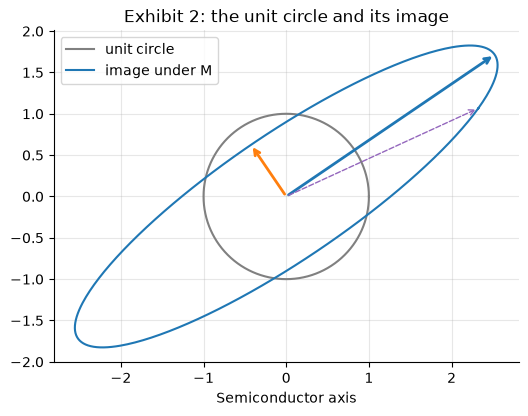

In [5]:
_, RSF = sample(["Semiconductor", "FinancialInsurance"])
M = cov0(RSF) * 1e4
print("M = 1e4 Sigma (computed):", M.round(4).tolist())
m11, m22, m12 = 2.3234, 1.4817, 1.0666                                  # the printed entries
half, root = (m11 + m22) / 2, math.sqrt((m11 - m22) ** 2 / 4 + m12**2)
l1, l2 = half + root, half - root
print(f"by hand: trace {m11 + m22:.4f}, half {half:.5f}, root {root:.5f}, lambda = {l1:.4f}, {l2:.4f}; "
      f"sum {l1 + l2:.4f}, product {l1 * l2:.4f}, det {m11 * m22 - m12**2:.4f}")
slope = (l1 - m11) / m12
print(f"q1: x2/x1 = {slope:.4f}, angle {math.degrees(math.atan(slope)):.1f} deg, q1 = {np.round([math.cos(math.atan(slope)), math.sin(math.atan(slope))], 3)}")
wM, QM = eig_desc(M)
print("eigh (sorted, signed):", wM.round(4), QM.round(3).tolist())
print(f"M e1 = {M[:, 0].round(4)}, {math.degrees(math.atan2(M[1, 0], M[0, 0])):.1f} deg from e1")
t = np.linspace(0, 2 * np.pi, 361)
circle = np.vstack([np.cos(t), np.sin(t)])
img = M @ circle
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.plot(*circle, color="grey", label="unit circle")
ax.plot(*img, color="tab:blue", label="image under M")
for k, col in ((0, "tab:blue"), (1, "tab:orange")):
    ax.annotate("", xy=wM[k] * QM[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=col, lw=2))
ax.annotate("", xy=M[:, 0], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:purple", ls="--"))
ax.set_aspect("equal"); ax.set_xlabel("Semiconductor axis"); ax.set_title("Exhibit 2: the unit circle and its image")
ax.legend(); plt.show()

## Part 4 — LM7's covariance matrix in its own axes (Example 2, Exhibit 3)

The total-return series of 0050 and 00679B are rebuilt as in LM7's lab: every ex-date of the dividend files (including 00679B's two with an unchanged close) and 0050's 4-for-1 split on 2025-06-18; each fund on its own calendar, returns between consecutive common dates from the base date 2017-01-17 ($T=2{,}363$, $A=243.0543$).

LM7's pair: T = 2,363, A = 243.0543; Sigma = [[0.040425, -0.002866], [-0.002866, 0.018214]], rho = -0.106
lambda = [0.040789 0.01785 ], q1 = [ 0.992 -0.126], tilt -7.24 deg, axis volatilities 20.20%, 13.36%


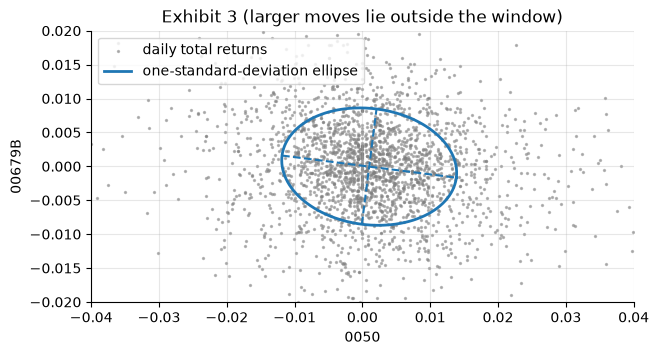

In [6]:
SPLITS = {"0050": ("2025-06-18", 4.0), "00631L": ("2026-03-31", 22.0)}

def fund(sym):
    # closes with the cash dividend D (0 when none) and the split ratio s (1 when none) on each date
    px = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    divf = DATA / f"{sym}_dividends.csv"
    div = (pl.read_csv(divf).select("date", pl.col("cash_dividend").alias("D")) if divf.exists()
           else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.String, "D": pl.Float64}))
    sdate, k = SPLITS.get(sym, ("", 1.0))
    return (px.join(div, on="date", how="left").sort("date")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sdate)).then(pl.lit(k)).otherwise(pl.lit(1.0)).alias("s")))

def tr_index(sym):
    # total-return index on the fund's own calendar: growth (P_t + D_t) / (P_{t-1} / s_t)
    f = fund(sym)
    return f.with_columns(((pl.col("close") + pl.col("D")) / (pl.col("close").shift(1) / pl.col("s"))).fill_null(1.0)
                          .cum_prod().alias(f"I_{sym}")).select("date", f"I_{sym}")

ix = (tr_index("0050").join(tr_index("00679B"), on="date", how="inner")
      .filter(pl.col("date") >= pl.lit("2017-01-17")).sort("date"))
r7 = ix.select(pl.col("date"), *[(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in ("I_0050", "I_00679B")]).drop_nulls()
X7 = r7.select("I_0050", "I_00679B").to_numpy()
T7 = X7.shape[0]; A7 = T7 / ((date(2026, 10, 8) - date(2017, 1, 17)).days / 365.25)
Sig7 = cov0(X7) * A7
print(f"LM7's pair: T = {T7:,}, A = {A7:.4f}; Sigma = {Sig7.round(6).tolist()}, rho = {corr(Sig7)[0, 1]:.3f}")
w7, Q7 = eig_desc(Sig7)
print(f"lambda = {w7.round(6)}, q1 = {Q7[:, 0].round(3)}, tilt {math.degrees(math.atan2(Q7[1, 0], Q7[0, 0])):.2f} deg, "
      f"axis volatilities {np.sqrt(w7[0]):.2%}, {np.sqrt(w7[1]):.2%}")
if FULL:
    assert T7 == 2363 and np.allclose(Sig7.round(6), [[0.040425, -0.002866], [-0.002866, 0.018214]])
S7d = cov0(X7); mu7 = X7.mean(axis=0); wd, Qd = eig_desc(S7d)
ell = mu7[:, None] + Qd @ np.diag(np.sqrt(wd)) @ np.vstack([np.cos(t), np.sin(t)])
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(X7[:, 0], X7[:, 1], s=2, color="grey", alpha=0.5, label="daily total returns")
ax.plot(*ell, color="tab:blue", lw=2, label="one-standard-deviation ellipse")
for k in range(2):
    a = np.sqrt(wd[k]) * Qd[:, k]
    ax.plot([mu7[0] - a[0], mu7[0] + a[0]], [mu7[1] - a[1], mu7[1] + a[1]], "--", color="tab:blue")
ax.set_xlim(-0.04, 0.04); ax.set_ylim(-0.02, 0.02); ax.set_aspect("equal")
ax.set_xlabel("0050"); ax.set_ylabel("00679B"); ax.set_title("Exhibit 3 (larger moves lie outside the window)")
ax.legend(loc="upper left"); plt.show()

## Part 5 — Rank-one pieces, $Q^{\top}Q=I$ and the sign rule (Example 3)

$\hat\Sigma=\sum_k\lambda_k\mathbf q_k\mathbf q_k^{\top}$ (11.3). The pieces are computed from the printed four-decimal eigenpairs, as a reader would, and then compared with the matrix.

In [7]:
_, R3 = sample(S3)
S3h = cov0(R3) * 1e4
w3, Q3 = eig_desc(S3h)
print("1e4 Sigma (S3):", S3h.round(4).tolist())
print("eigenvalues:", w3.round(4), " Q:", Q3.round(4).tolist())
print("Q'Q = I:", np.allclose(Q3.T @ Q3, np.eye(3)), "  Q Q' = I:", np.allclose(Q3 @ Q3.T, np.eye(3)))
w3r, Q3r = w3.round(4), Q3.round(4)
pieces = [np.round(w3r[k] * np.outer(Q3r[:, k], Q3r[:, k]), 3) for k in range(3)]
for k, p_ in enumerate(pieces, 1):
    print(f"piece {k}:", p_.tolist())
print(f"largest gap between the sum of the printed pieces and the printed matrix: {np.abs(sum(pieces) - S3h.round(4)).max():.4f}")
print(f"trace {np.trace(S3h):.4f} = sum of eigenvalues {w3.sum():.4f}; first share {w3[0] / w3.sum():.1%}")
v = np.array([-1.0, 1.0]) / math.sqrt(2)
print("sign rule on a tie, (-1, 1)/sqrt 2 ->", sign_rule(v).round(4), "  on (0.3, -0.8, 0.5) ->", sign_rule(np.array([0.3, -0.8, 0.5])))

1e4 Sigma (S3): [[2.3234, 1.0666, 0.661], [1.0666, 1.4817, 0.7795], [0.661, 0.7795, 1.155]]
eigenvalues: [3.4728 0.9944 0.4929]  Q: [[0.7366, 0.6526, -0.1774], [0.5492, -0.424, 0.7202], [0.3948, -0.6279, -0.6707]]
Q'Q = I: True   Q Q' = I: True
piece 1: [[1.884, 1.405, 1.01], [1.405, 1.047, 0.753], [1.01, 0.753, 0.541]]
piece 2: [[0.424, -0.275, -0.407], [-0.275, 0.179, 0.265], [-0.407, 0.265, 0.392]]
piece 3: [[0.016, -0.063, 0.059], [-0.063, 0.256, -0.238], [0.059, -0.238, 0.222]]
largest gap between the sum of the printed pieces and the printed matrix: 0.0010
trace 4.9601 = sum of eigenvalues 4.9601; first share 70.0%
sign rule on a tie, (-1, 1)/sqrt 2 -> [ 0.7071 -0.7071]   on (0.3, -0.8, 0.5) -> [-0.3  0.8 -0.5]


## Part 6 — The Rayleigh quotient and condition numbers (Exhibit 4, Exhibit 5, Example 4)

Every unit vector has $\lambda_N\le\mathbf u^{\top}M\mathbf u\le\lambda_1$ (11.4). Random unit vectors never beat $\lambda_1$; the condition numbers of Exhibit 5 use the U28 sample except for the two ETF pairs, LM7's (Part 4) and LM8's 0050/00631L (LM1's 2,902 total returns on common dates). The last cell checks LM7's gradient factor $(\kappa-1)/(\kappa+1)$.

h(u): max 3.0492 at 34.2 deg, min 0.7559 at 124.2 deg


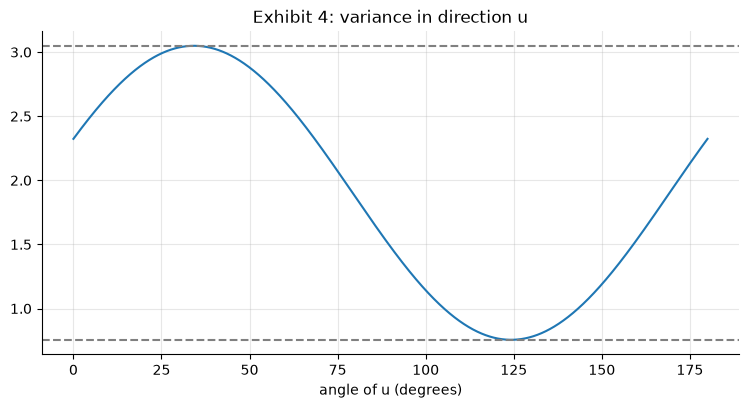

100,000 random unit vectors on U28's C: largest h 8.096 <= lambda_1 14.721; smallest 0.313 >= lambda_N 0.2084
equal weights: h(1/sqrt N) = 1 + 27 rho_bar = 14.561 <= lambda_1 = 14.721


In [8]:
th = np.radians(np.arange(0, 180.0001, 0.01))
U = np.vstack([np.cos(th), np.sin(th)])
hth = np.einsum("in,ij,jn->n", U, M, U)
print(f"h(u): max {hth.max():.4f} at {np.degrees(th[hth.argmax()]):.1f} deg, min {hth.min():.4f} at {np.degrees(th[hth.argmin()]):.1f} deg")
fig, ax = plt.subplots()
ax.plot(np.degrees(th), hth); ax.axhline(wM[0], ls="--", color="grey"); ax.axhline(wM[1], ls="--", color="grey")
ax.set_xlabel("angle of u (degrees)"); ax.set_title("Exhibit 4: variance in direction u"); plt.show()
rng = np.random.default_rng(20261011)
Z = rng.standard_normal((100_000, N)); Z /= np.linalg.norm(Z, axis=1, keepdims=True)
hz = np.einsum("ij,jk,ik->i", Z, C, Z)
print(f"100,000 random unit vectors on U28's C: largest h {hz.max():.3f} <= lambda_1 {lam[0]:.3f}; smallest {hz.min():.3f} >= lambda_N {lam[-1]:.4f}")
print(f"equal weights: h(1/sqrt N) = 1 + 27 rho_bar = {1 + (N - 1) * off.mean():.3f} <= lambda_1 = {lam[0]:.3f}")

In [9]:
# LM1's frame for 0050 / 00631L: common dates, total returns (P_t + D_t) / (P_{t-1} / s_t) - 1
def frame_lm1():
    a = fund("0050").rename({"close": "p_a", "D": "d_a", "s": "s_a"})
    b = fund("00631L").rename({"close": "p_b", "D": "d_b", "s": "s_b"})
    j = a.join(b, on="date", how="inner").sort("date")
    j = j.with_columns(((pl.col("p_a") + pl.col("d_a")) / (pl.col("p_a").shift(1) / pl.col("s_a")) - 1).alias("R_a"),
                       ((pl.col("p_b") + pl.col("d_b")) / (pl.col("p_b").shift(1) / pl.col("s_b")) - 1).alias("R_b"))
    return j.drop_nulls("R_a").select("R_a", "R_b").to_numpy()

X1 = frame_lm1()
rho1 = np.corrcoef(X1.T)[0, 1]
print(f"0050 / 00631L: T = {X1.shape[0]:,}, rho = {rho1:.6f}, kappa(C) = (1 + rho)/(1 - rho) = {(1 + rho1) / (1 - rho1):.2f}")
def kap(m):
    w = np.linalg.eigvalsh(m)
    return w.max() / w.min()
rows = [("0050, 00679B (LM7)", 2, kap(corr(S7d)), kap(S7d)), ("0050, 00631L (LM8)", 2, kap(corr(cov0(X1))), kap(cov0(X1)))]
for lab, cols in (("Semiconductor, FinancialInsurance", S3[:2]), ("S3", S3), ("S5", S5), ("U28", U28),
                  ("Electronic and its eight", ["Electronic"] + ELEC8), ("All 30", SECTORS)):
    sig = cov0(sample(cols)[1])
    rows.append((lab, len(cols), kap(corr(sig)), kap(sig)))
ladder = pl.DataFrame(rows, schema=["assets", "N", "kappa(C)", "kappa(Sigma)"], orient="row")
print("np.linalg.cond equals lambda_1 / lambda_N for U28's Sigma:", np.isclose(np.linalg.cond(S), kap(S)))
ladder   # Exhibit 5

0050 / 00631L: T = 2,902, rho = 0.974365, kappa(C) = (1 + rho)/(1 - rho) = 77.02
np.linalg.cond equals lambda_1 / lambda_N for U28's Sigma: True


assets,N,kappa(C),kappa(Sigma)
str,i64,f64,f64
"""0050, 00679B (LM7)""",2,1.2362,2.2851
"""0050, 00631L (LM8)""",2,77.0178,116.8448
"""Semiconductor, FinancialInsura…",2,3.7043,4.0337
"""S3""",3,5.8823,7.0449
"""S5""",5,8.5162,12.1177
"""U28""",28,70.6368,108.0852
"""Electronic and its eight""",9,836.3453,925.2725
"""All 30""",30,2265.7246,2410.6698


In [10]:
# LM7's gradient ascent on its quadratic model: with alpha = 2 / (l1 + lN), every step multiplies the error along
# q_k by 1 - alpha l_k, so the distance shrinks at least by (kappa - 1)/(kappa + 1)
l1_, lN_ = w7
alpha = 2 / (l1_ + lN_)
print(f"alpha = {alpha:.1f}; factors 1 - alpha*lambda: {1 - alpha * l1_:+.3f}, {1 - alpha * lN_:+.3f}; (kappa-1)/(kappa+1) = {(l1_ - lN_) / (l1_ + lN_):.3f}")
err = np.array([1.0, 1.0])
for step in range(3):
    err = (np.eye(2) - alpha * Sig7) @ err
    print(f"step {step + 1}: distance {np.linalg.norm(err):.4f}")

alpha = 34.1; factors 1 - alpha*lambda: -0.391, +0.391; (kappa-1)/(kappa+1) = 0.391
step 1: distance 0.5532
step 2: distance 0.2164
step 3: distance 0.0847


## Part 7 — Principal component analysis of U28 (Example 5, Exhibit 6, Exhibit 7, Exhibit 8, Example 6)

Scree, loadings, scores $\xi_{k,t}=\mathbf q_k^{\top}\operatorname{diag}(\mathbf s)^{-1}(\mathbf R_t-\bar{\mathbf R})$ with $\operatorname{Var}\xi_k=\lambda_k$, covariance against correlation PCA, and a change of units.

lambda_1 = 14.7214 (52.58%), lambda_2 = 1.4837 (5.30%); cumulative: 11 components 79.31%, 12 components 80.93%


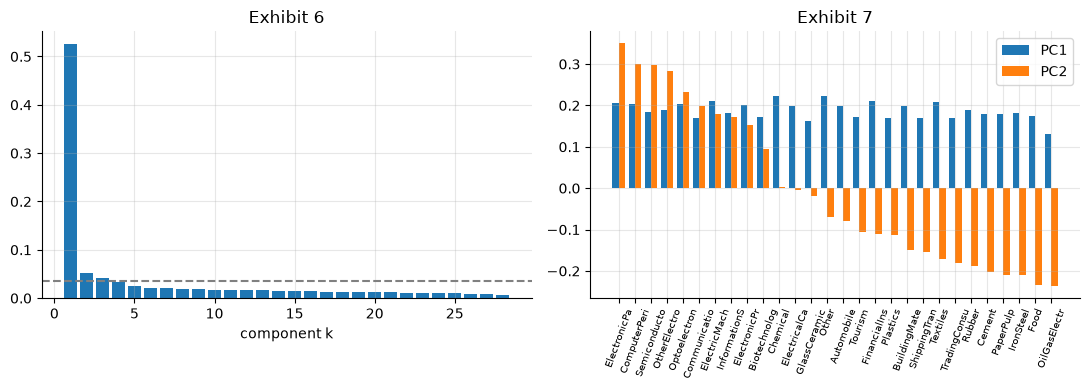

Var(xi_k) - lambda_k: max 5.3e-15; largest covariance of two scores 1.4e-15
Exhibit 8: covariance shares 51.70%, 5.88%; correlation 52.58%, 5.30%; |cos| of the two PC1 0.9791
largest PC2 loading: covariance 0.667 (GlassCeramic, volatility 35.31%, the highest is GlassCeramic); correlation 0.350 (ElectronicPartsComponents)
Example 6: covariance PC1 [1.     0.0046], share 99.996%; correlation eigenvalues [1.5749 0.4251], q1 [0.7071 0.7071]


In [11]:
print(f"lambda_1 = {lam[0]:.4f} ({lam[0] / N:.2%}), lambda_2 = {lam[1]:.4f} ({lam[1] / N:.2%}); "
      f"cumulative: 11 components {cum[10]:.2%}, 12 components {cum[11]:.2%}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(np.arange(1, N + 1), lam / N); axs[0].axhline(1 / N, ls="--", color="grey")
axs[0].set_title("Exhibit 6"); axs[0].set_xlabel("component k")
order = np.argsort(-Q[:, 1], kind="stable")
axs[1].bar(np.arange(N) - 0.2, Q[order, 0], width=0.4, label="PC1"); axs[1].bar(np.arange(N) + 0.2, Q[order, 1], width=0.4, label="PC2")
axs[1].set_xticks(np.arange(N), [U28[i][:12] for i in order], rotation=70, fontsize=7); axs[1].legend()
axs[1].set_title("Exhibit 7"); plt.tight_layout(); plt.show()
s = np.sqrt(np.diag(S))
XI = ((R - R.mean(axis=0)) / s) @ Q                     # scores, one column per component
cx = XI.T @ XI / T
print(f"Var(xi_k) - lambda_k: max {np.abs(np.diag(cx) - lam).max():.1e}; largest covariance of two scores {np.abs(cx - np.diag(np.diag(cx))).max():.1e}")
lamS, QS = eig_desc(S)
vols = np.sqrt(A * np.diag(S))
print(f"Exhibit 8: covariance shares {lamS[0] / lamS.sum():.2%}, {lamS[1] / lamS.sum():.2%}; correlation {lam[0] / N:.2%}, {lam[1] / N:.2%}; "
      f"|cos| of the two PC1 {abs(QS[:, 0] @ Q[:, 0]):.4f}")
print(f"largest PC2 loading: covariance {QS[:, 1].max():.3f} ({U28[int(QS[:, 1].argmax())]}, volatility {vols[int(QS[:, 1].argmax())]:.2%}, "
      f"the highest is {U28[int(vols.argmax())]}); correlation {Q[:, 1].max():.3f} ({U28[int(Q[:, 1].argmax())]})")
pct = RSF * np.array([100.0, 1.0])                      # Semiconductor in percent, FinancialInsurance in decimals
w6, Q6 = eig_desc(cov0(pct)); wc6, Qc6 = eig_desc(corr(cov0(pct)))
print(f"Example 6: covariance PC1 {Q6[:, 0].round(4)}, share {w6[0] / w6.sum():.3%}; correlation eigenvalues {wc6.round(4)}, q1 {Qc6[:, 0].round(4)}")

## Part 8 — Overlapping indices (Example 7, Exhibit 9)

In [12]:
for lab, cols in (("Electronic + eight", ["Electronic"] + ELEC8), ("all 30", SECTORS)):
    wv, Qv = eig_desc(corr(cov0(sample(cols)[1])))
    for k in (-1, -2):
        if lab.startswith("Electronic") and k == -2:
            continue
        o = np.argsort(-np.abs(Qv[:, k]))[:3]
        print(f"{lab}: lambda = {wv[k]:.5f}, largest entries", [(cols[i], round(float(Qv[i, k]), 3)) for i in o])
    print(f"   kappa(C) = {wv[0] / wv[-1]:,.1f}")
print(f"U28's smallest eigenvalue: {lam[-1]:.4f}")

Electronic + eight: lambda = 0.00730, largest entries [('Electronic', 0.828), ('Semiconductor', -0.529), ('ElectronicPartsComponents', -0.104)]
   kappa(C) = 836.3
all 30: lambda = 0.00711, largest entries [('Electronic', 0.826), ('Semiconductor', -0.53), ('ElectronicPartsComponents', -0.103)]
all 30: lambda = 0.01517, largest entries [('ChemicalBiotechnologyMedicalCare', 0.771), ('Chemical', -0.473), ('BiotechnologyMedicalCare', -0.425)]
   kappa(C) = 2,265.7
U28's smallest eigenvalue: 0.2084


## Part 9 — Eigenvalue gaps and stability (Example 8, Exhibit 10, Exhibit 11, Exhibit 12)

(11.9): a diagonal matrix with neighbouring eigenvalues and $\varepsilon$ off the diagonal turns its eigenvectors by $\tfrac12\arctan(2\varepsilon/\text{gap})\approx\varepsilon/\text{gap}$. Then each calendar year against the full sample, and the two halves. This is a **stability check**: the full-sample reference could not have been known inside a year, and nothing here is an out-of-sample test.

In [13]:
eps = 0.05
for a_, b_ in ((1, 2), (6, 7)):
    gap = lam[a_] - lam[b_]
    print(f"lambda_{a_ + 1} = {lam[a_]:.5f}, lambda_{b_ + 1} = {lam[b_]:.5f}, gap {gap:.5f}: exact {math.degrees(0.5 * math.atan(2 * eps / gap)):.2f} deg, "
          f"first order {math.degrees(eps / gap):.2f} deg")
# numerical check of (11.9) on a 2 x 2 matrix
Mt = np.array([[lam[1], eps], [eps, lam[2]]])
wt, Qt = eig_desc(Mt)
print(f"eigh on [[lambda_2, eps], [eps, lambda_3]]: q1 at {math.degrees(math.atan2(Qt[1, 0], Qt[0, 0])):.2f} deg")
ytab = []
for y in range(2009, 2027):
    wy, Qy = eig_desc(corr(cov0(R[yr == y])))
    ytab.append({"year": y, "returns": int((yr == y).sum()), "share PC1": wy[0] / N, "|cos q1|": abs(Qy[:, 0] @ Q[:, 0]),
                 "|cos q2|": abs(Qy[:, 1] @ Q[:, 1]),
                 "plane measure": math.hypot(Q[:, 1] @ Qy[:, 1], Q[:, 2] @ Qy[:, 1]), "gap 2-3": wy[1] - wy[2]})
ytab = pl.DataFrame(ytab)
ytab   # Exhibit 10 and Exhibit 11; 2026 runs to 8 October

lambda_2 = 1.48370, lambda_3 = 1.14694, gap 0.33676: exact 8.27 deg, first order 8.51 deg
lambda_7 = 0.58028, lambda_8 = 0.54445, gap 0.03583: exact 35.14 deg, first order 79.96 deg
eigh on [[lambda_2, eps], [eps, lambda_3]]: q1 at 8.27 deg


year,returns,share PC1,|cos q1|,|cos q2|,plane measure,gap 2-3
i64,i64,f64,f64,f64,f64,f64
2009,251,0.6267,0.9974,0.2925,0.9192,0.2873
2010,251,0.6023,0.9980,0.7589,0.8966,0.1943
2011,247,0.6641,0.9975,0.3631,0.9382,0.2918
2012,250,0.5893,0.9977,0.5129,0.9357,0.7099
2013,246,0.4489,0.9926,0.2594,0.8400,0.3840
2014,248,0.4677,0.9969,0.4333,0.8272,0.5730
2015,244,0.5744,0.9979,0.2338,0.8485,0.4279
2016,244,0.5014,0.9949,0.1193,0.7432,0.4937
2017,246,0.3452,0.9927,0.4627,0.8007,0.3213


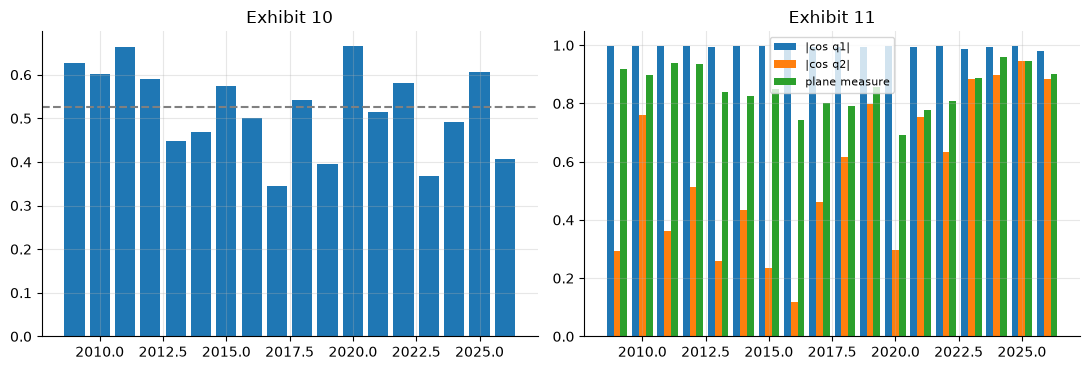

shares 57.6% and 49.2%; signed cos of PC2 -0.2966; with the first half's q3 0.8787; plane measure 0.9274, an angle of 22 deg
PC2's largest loading: first half OilGasElectricity 0.572; second half ElectronicPartsComponents 0.341


k,lambda first half,lambda second half,|cos|
i64,f64,f64,f64
1,16.1163,13.7869,0.9971
2,1.2621,1.8483,0.2966
3,1.0688,1.1714,0.1206
4,0.6663,1.1023,0.0431
5,0.6194,0.7397,0.4279


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].bar(ytab["year"], ytab["share PC1"]); axs[0].axhline(lam[0] / N, ls="--", color="grey"); axs[0].set_title("Exhibit 10")
for k, (c, off_) in enumerate((("|cos q1|", -0.27), ("|cos q2|", 0.0), ("plane measure", 0.27))):
    axs[1].bar(ytab["year"] + off_, ytab[c], width=0.27, label=c)
axs[1].legend(fontsize=8); axs[1].set_title("Exhibit 11"); plt.tight_layout(); plt.show()
wa, Qa = eig_desc(corr(S1)); wb, Qb = eig_desc(corr(S2))
halves = pl.DataFrame({"k": list(range(1, 6)), "lambda first half": wa[:5], "lambda second half": wb[:5],
                       "|cos|": [abs(Qa[:, k] @ Qb[:, k]) for k in range(5)]})
c22, c23 = Qa[:, 1] @ Qb[:, 1], Qa[:, 2] @ Qb[:, 1]
print(f"shares {wa[0] / N:.1%} and {wb[0] / N:.1%}; signed cos of PC2 {c22:.4f}; with the first half's q3 {c23:.4f}; "
      f"plane measure {math.hypot(c22, c23):.4f}, an angle of {math.degrees(math.acos(math.hypot(c22, c23))):.0f} deg")
print(f"PC2's largest loading: first half {U28[int(np.abs(Qa[:, 1]).argmax())]} {Qa[np.abs(Qa[:, 1]).argmax(), 1]:.3f}; "
      f"second half {U28[int(np.abs(Qb[:, 1]).argmax())]} {Qb[np.abs(Qb[:, 1]).argmax(), 1]:.3f}")
halves   # Exhibit 12

## Part 10 — The inverse of $\hat\Sigma$ (Example 9, Example 10, Exhibit 13, Exhibit 14)

(11.7): $\hat\Sigma^{-1}\mathbf b=\sum_k(\mathbf q_k^{\top}\mathbf b/\lambda_k)\,\mathbf q_k$; (11.8): $\lVert\Delta\mathbf x\rVert/\lVert\mathbf x+\Delta\mathbf x\rVert\le\kappa\lVert\Delta M\rVert_2/\lVert M\rVert_2$ in the spectral norm. Systems are solved with `np.linalg.solve`, never with `inv`.

Example 9: x = [10.256 -9.744] -> [ 12.755 -12.245]; relative change 0.19996; bound 0.2000
U28: relative change 0.729, cosine 0.690, kappa 126.05, ||dS||/||S|| 0.24536, bound 30.93
first half: PC1 gives 1.8% of ||x||^2, the 14 smallest components 72.0%
second half: PC1 gives 1.0% of ||x||^2, the 14 smallest components 80.5%
S5: x(1) = [ 2290.29 -1013.59  3271.34  2591.12  2279.27], x(2) = [ -23.72 5609.   9584.83 -281.56   49.08]; relative change 0.910, cosine 0.419, kappa 10.863, bound 4.805


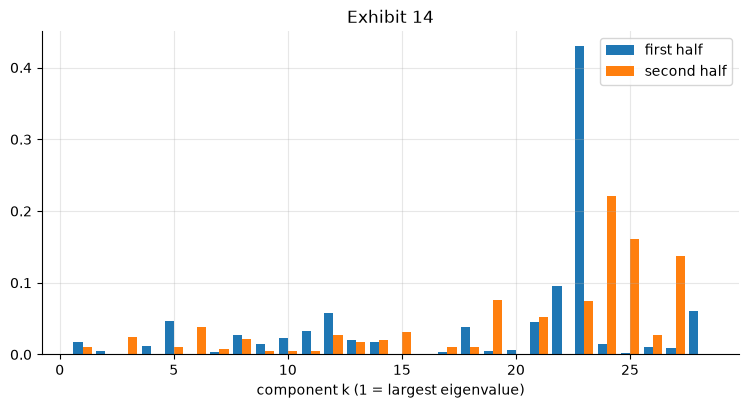

In [15]:
def rel_and_bound(Ma, Mb, b):
    xa, xb = np.linalg.solve(Ma, b), np.linalg.solve(Mb, b)
    return xa, xb, np.linalg.norm(xb - xa) / np.linalg.norm(xb), kap(Ma) * spec_norm(Mb - Ma) / spec_norm(Ma)

Ca, Cb = np.array([[1, 0.95], [0.95, 1]]), np.array([[1, 0.96], [0.96, 1]])
xa, xb, rel, bnd = rel_and_bound(Ca, Cb, np.array([1.0, 0.0]))
print(f"Example 9: x = {xa.round(3)} -> {xb.round(3)}; relative change {rel:.5f}; bound {bnd:.4f}")
_, _, rel, bnd = rel_and_bound(S1, S2, np.ones(N))
print(f"U28: relative change {rel:.3f}, cosine {x1 @ x2 / np.linalg.norm(x1) / np.linalg.norm(x2):.3f}, "
      f"kappa {kap(S1):.2f}, ||dS||/||S|| {spec_norm(S2 - S1) / spec_norm(S1):.5f}, bound {bnd:.2f}")
shares = {}
for lab, Sh, xh in (("first half", S1, x1), ("second half", S2, x2)):
    wh, Qh = eig_desc(Sh)
    c = (Qh.T @ np.ones(N) / wh) ** 2 / (xh @ xh)
    assert np.allclose(Qh @ (Qh.T @ np.ones(N) / wh), xh)          # (11.7) rebuilds the solution
    shares[lab] = c
    print(f"{lab}: PC1 gives {c[0]:.1%} of ||x||^2, the 14 smallest components {c[14:].sum():.1%}")
_, R5 = sample(S5)
xs5a, xs5b, rel5, bnd5 = rel_and_bound(cov0(R5[:h]), cov0(R5[h:]), np.ones(5))
print(f"S5: x(1) = {xs5a.round(2)}, x(2) = {xs5b.round(2)}; relative change {rel5:.3f}, cosine "
      f"{xs5a @ xs5b / np.linalg.norm(xs5a) / np.linalg.norm(xs5b):.3f}, kappa {kap(cov0(R5[:h])):.3f}, bound {bnd5:.3f}")
fig, ax = plt.subplots()
ks = np.arange(1, N + 1)
ax.bar(ks - 0.2, shares["first half"], width=0.4, label="first half"); ax.bar(ks + 0.2, shares["second half"], width=0.4, label="second half")
ax.set_xlabel("component k (1 = largest eigenvalue)"); ax.set_title("Exhibit 14"); ax.legend(); plt.show()

## Part 11 — Practice problems 5–12

Problems 5–10 work from the printed inputs, as the solutions do; 11 and 12 are the Python problems.

In [16]:
# Problem 5: Plastics / Food from the printed entries
p11, p22, p12 = 2.5228, 1.1550, 0.7180
half5, root5 = (p11 + p22) / 2, math.sqrt((p11 - p22) ** 2 / 4 + p12**2)
l15, l25 = half5 + root5, half5 - root5
sl5 = (l15 - p11) / p12
print(f"P5: lambda {l15:.4f}, {l25:.4f}; q1 {np.round([math.cos(math.atan(sl5)), math.sin(math.atan(sl5))], 3)} at "
      f"{math.degrees(math.atan(sl5)):.1f} deg; share {l15 / (p11 + p22):.1%}; kappa {l15 / l25:.2f}")
print("   computed matrix:", (cov0(sample(["Plastics", "Food"])[1]) * 1e4).round(4).tolist())
# Problem 6: equicorrelation N = 5, rho = 0.5, against S5's correlation matrix
C5 = corr(cov0(R5)); w5, Q5 = eig_desc(C5)
rb5 = C5[np.triu_indices(5, 1)].mean()
print(f"P6: equicorrelation eigenvalues {np.linalg.eigvalsh(0.5 * np.eye(5) + 0.5 * np.ones((5, 5)))[::-1].round(4)}; "
      f"S5: lambda_1 {w5[0]:.4f}, lambda_5 {w5[-1]:.4f}, share {w5[0] / 5:.1%}, kappa {w5[0] / w5[-1]:.2f}, "
      f"rho bar {rb5:.3f}; 1 + 4 x 0.462 = {1 + 4 * 0.462:.3f} from the printed rho bar ({1 + 4 * rb5:.3f} unrounded)")
# Problem 7: rebuild from lambda = 4, 1 and theta = 30 degrees
q = np.array([math.cos(math.pi / 6), math.sin(math.pi / 6)]); q2 = np.array([-q[1], q[0]])
M7 = 4 * np.outer(q, q) + np.outer(q2, q2)
print(f"P7: {M7.round(4).tolist()}, trace {np.trace(M7):.4f}, det {np.linalg.det(M7):.4f}")
# Problem 8: rows (2, eps) and (eps, 1)
for e_ in (0.1, 0.5):
    w8, Q8 = eig_desc(np.array([[2, e_], [e_, 1]]))
    print(f"P8: eps {e_}: eigh angle {math.degrees(math.atan2(Q8[1, 0], Q8[0, 0])):.2f} deg, first order {math.degrees(e_):.2f} deg")
# Problem 9
print(f"P9: rho for kappa 100 = {99 / 101:.4f}; 0050/00631L kappa(C) = {(1 + rho1) / (1 - rho1):.2f}")
# Problem 10
print(f"P10: S5 bound {bnd5:.3f}, realized {rel5:.3f} ({rel5 / bnd5:.2f} of the bound); U28 realized / bound "
      f"{np.linalg.norm(x2 - x1) / np.linalg.norm(x2) / (kap(S1) * spec_norm(S2 - S1) / spec_norm(S1)):.3f}; "
      f"kappa ratio {kap(S1) / kap(cov0(R5[:h])):.1f}")

P5: lambda 2.8305, 0.8473; q1 [0.919 0.394] at 23.2 deg; share 77.0%; kappa 3.34
   computed matrix: [[2.5228, 0.718], [0.718, 1.155]]
P6: equicorrelation eigenvalues [3.  0.5 0.5 0.5 0.5]; S5: lambda_1 2.8633, lambda_5 0.3362, share 57.3%, kappa 8.52, rho bar 0.462; 1 + 4 x 0.462 = 2.848 from the printed rho bar (2.849 unrounded)
P7: [[3.25, 1.299], [1.299, 1.75]], trace 5.0000, det 4.0000
P8: eps 0.1: eigh angle 5.65 deg, first order 5.73 deg
P8: eps 0.5: eigh angle 22.50 deg, first order 28.65 deg
P9: rho for kappa 100 = 0.9802; 0050/00631L kappa(C) = 77.02
P10: S5 bound 4.805, realized 0.910 (0.19 of the bound); U28 realized / bound 0.024; kappa ratio 11.6


In [17]:
# Problem 11 (Python): S5 correlation PCA, signed loadings, scores
print("P11: eigenvalues", w5.round(4), " sum", round(float(w5.sum()), 4))
print(pl.DataFrame({"sector": S5, **{f"q{k + 1}": Q5[:, k].round(3) for k in range(5)}}))
s5 = np.sqrt(np.diag(cov0(R5)))
XI5 = ((R5 - R5.mean(axis=0)) / s5) @ Q5
c5 = XI5.T @ XI5 / R5.shape[0]
print("Var(xi_k):", np.diag(c5).round(4), " largest covariance of two scores:", f"{np.abs(c5 - np.diag(np.diag(c5))).max():.1e}")
# Problem 12 (Python): per year, from the table of Part 9
g = ytab.sort("gap 2-3").row(0, named=True)
print(f"P12: smallest gap lambda_2 - lambda_3 in {g['year']}: {g['gap 2-3']:.3f}; |cos q1| >= {ytab['|cos q1|'].min():.3f}; "
      f"|cos q2| {ytab['|cos q2|'].min():.3f} .. {ytab['|cos q2|'].max():.3f}; plane {ytab['plane measure'].min():.3f} .. {ytab['plane measure'].max():.3f}")

P11: eigenvalues [2.8633 0.6674 0.5895 0.5436 0.3362]  sum 5.0
shape: (5, 6)
┌────────────────────────┬────────┬─────────┬─────────┬─────────┬─────────┐
│ sector                 ┆ q1     ┆ q2      ┆ q3      ┆ q4      ┆ q5      │
│ ---                    ┆ ---    ┆ ---     ┆ ---     ┆ ---     ┆ ---     │
│ str                    ┆ f64    ┆ f64     ┆ f64     ┆ f64     ┆ f64     │
╞════════════════════════╪════════╪═════════╪═════════╪═════════╪═════════╡
│ Semiconductor          ┆ 0.4410 ┆ -0.3820 ┆ -0.4550 ┆ -0.5910 ┆ -0.3220 │
│ FinancialInsurance     ┆ 0.5100 ┆ 0.0040  ┆ 0.0970  ┆ -0.1540 ┆ 0.8410  │
│ Food                   ┆ 0.4440 ┆ 0.1690  ┆ 0.7730  ┆ -0.1620 ┆ -0.3880 │
│ Plastics               ┆ 0.4290 ┆ -0.5030 ┆ -0.0410 ┆ 0.7400  ┆ -0.1180 │
│ ShippingTransportation ┆ 0.4060 ┆ 0.7570  ┆ -0.4300 ┆ 0.2300  ┆ -0.1570 │
└────────────────────────┴────────┴─────────┴─────────┴─────────┴─────────┘
Var(xi_k): [2.8633 0.6674 0.5895 0.5436 0.3362]  largest covariance of two scores: 5.6e

## Part 12 — Extension: the first component's share over rolling windows

The module compares calendar years. Here the first component's share of U28's correlation matrix is computed over rolling windows of 250 returns, every fifth date: a **descriptive** picture, not in the text.

1. When was the share highest and lowest, and which market episodes do those windows contain?
2. Repeat with windows of 60 returns. How much of the movement is sampling noise? [[LM20]] gives the tools to answer; here, compare the two curves.
3. Track $\lvert\cos\theta\rvert$ between each window's $\mathbf q_1$ and the full sample's. Does the first direction ever turn by more than 15°?

rolling 250-return share of PC1: lowest 33.4% (window ending 2018-01-23), highest 71.7% (ending 2012-08-01)


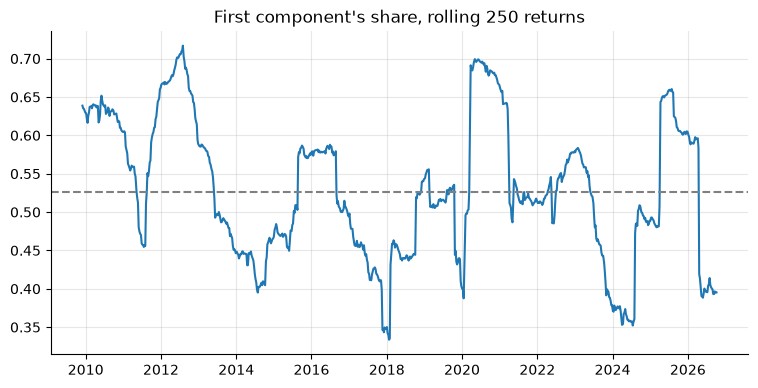

In [18]:
W = 250
ends = list(range(W, T + 1, 5))
roll = pl.DataFrame({"end": [dates[e - 1] for e in ends],
                     "share": [np.linalg.eigvalsh(corr(cov0(R[e - W:e])))[-1] / N for e in ends]})
lo_, hi_ = roll.sort("share").row(0), roll.sort("share").row(-1)
print(f"rolling {W}-return share of PC1: lowest {lo_[1]:.1%} (window ending {lo_[0]}), highest {hi_[1]:.1%} (ending {hi_[0]})")
fig, ax = plt.subplots()
ax.plot([date.fromisoformat(d) for d in roll["end"]], roll["share"])
ax.axhline(lam[0] / N, ls="--", color="grey"); ax.set_title(f"First component's share, rolling {W} returns"); plt.show()